In [53]:
import numpy as np
import pandas as pd
import seaborn as sns
# For train & split
from sklearn.model_selection import train_test_split
# For Linear Regression
from sklearn.linear_model import LinearRegression
# for Evaluating by r2
from sklearn.metrics import r2_score

In [54]:
# Fetch the data:
insurance_data = pd.read_csv("insurance.csv")

In [55]:
# Printing the data :
insurance_data

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


### Visualize:

<Axes: xlabel='bmi', ylabel='charges'>

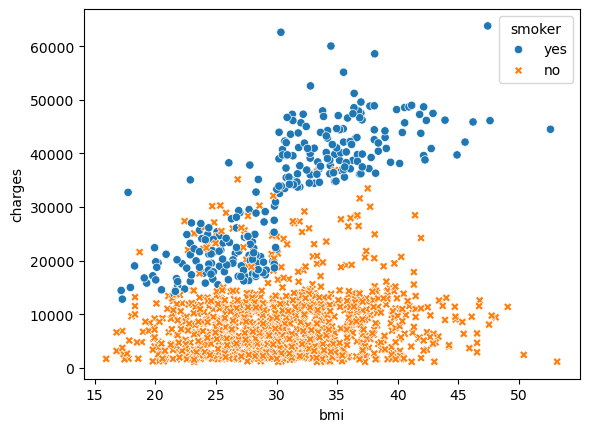

In [56]:
sns.scatterplot(data=insurance_data, x="bmi", y="charges", hue="smoker" , style="smoker")

In [57]:
# Separate input & output:
X = insurance_data.drop(["charges" , "region"] ,axis= 1)
y = insurance_data["charges"]

# Encode the string values to numeric values:
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})
X["sex"] = X["sex"].map({"female": 1, "male": 0})

In [58]:
X.head()

,age,sex,bmi,children,smoker
0,19,1,27.900,0,1
1,18,0,33.770,1,0
2,28,0,33.000,3,0
3,33,0,22.705,0,0
4,32,0,28.880,0,0


In [59]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [60]:
# test and split By 80 - 20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [61]:
# Instantiate linear regression model.
model = LinearRegression()

In [62]:
# Fit the model to the training data.
model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [63]:
# Make predictions on the testing data.
y_pred = model.predict(X_test)

In [ ]:
y_pred

In [ ]:
y_test

## Evaluating:

In [66]:
# r^2 value:
r_squared = r2_score(y_test, y_pred)
r_squared

0.7811302113434095

In [67]:
# Adhusted R-squared value
n = X_test.shape[0]
p = X_test.shape[1]

adj_r2 = 1 - ((1 - r_squared) * (n - 1) / (n - p - 1))
adj_r2

0.7769533069797342

### After One Hot Encoding of he Regions Column:

In [68]:
# Separate input & output:
X = insurance_data.drop(["charges"] ,axis= 1)
y = insurance_data["charges"]

# Encode the string values to numeric values:
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})
X["sex"] = X["sex"].map({"female": 1, "male": 0})

In [69]:
# One Hot Encoding
X = pd.get_dummies(X , columns = ["region"] ,drop_first= True ,dtype=int)

In [70]:
# test and split By 80 - 20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Instantiate linear regression model.
model = LinearRegression()

# Fit the model to the training data.
model.fit(X_train, y_train)

# Make predictions on the testing data.
y_pred = model.predict(X_test)

In [71]:
# r^2 value:
r_squared = r2_score(y_test, y_pred)
r_squared

0.7835929767120724

## After making an Interaction Feature:

In [72]:
# Separate input & output:
X = insurance_data.drop(["charges"] ,axis= 1)
y = insurance_data["charges"]

# Encode the string values to numeric values:
X["smoker"] = X["smoker"].map({"yes": 1, "no": 0})
X["sex"] = X["sex"].map({"female": 1, "male": 0})

# One Hot Encoding
X = pd.get_dummies(X , columns = ["region"] ,drop_first= True ,dtype=int)

In [73]:
# Interaction Features:
X["age_smoker"] = X["age"] * X["smoker"]
X["bmi_smoker"] = X["bmi"] * X["smoker"]

In [74]:
X.head()

,age,sex,bmi,children,smoker,region_northwest,region_southeast,region_southwest,age_smoker,bmi_smoker
0,19,1,27.900,0,1,0,0,1,19,27.9
1,18,0,33.770,1,0,0,1,0,0,0.0
2,28,0,33.000,3,0,0,1,0,0,0.0
3,33,0,22.705,0,0,1,0,0,0,0.0
4,32,0,28.880,0,0,1,0,0,0,0.0


In [75]:
# test and split By 80 - 20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Instantiate linear regression model.
model = LinearRegression()

# Fit the model to the training data.
model.fit(X_train, y_train)

# Make predictions on the testing data.
y_pred = model.predict(X_test)

In [80]:
# r^2 value:
r_squared_test = r2_score(y_test, y_pred)
r_squared_test

0.865231697953168

## Is model Underfit or overfit ???

In [81]:
# if r2 training and testing is low ----> underfit (high bias , low variance)
# if r2 training > then the testing ----> overfit  (low bias , high variance)

In [84]:
y_train_pred = model.predict(X_train)

r_squared_train = r2_score(y_train , y_train_pred)

print(f"The R2 of testing is : {r_squared_test}")
print(f"The R2 of traning is : {r2_squared_train}")

The R2 of testing is : 0.865231697953168
The R2 of traning is : 0.8340713711218875
